# Детекция. YOLO

In [4]:
!pip3 install ultralytics -qq       # YOLO
!pip3 install opencv-python         # CV2 для захвата с камеры

### Варианты YOLOv11  

Таблица вариантов YOLO

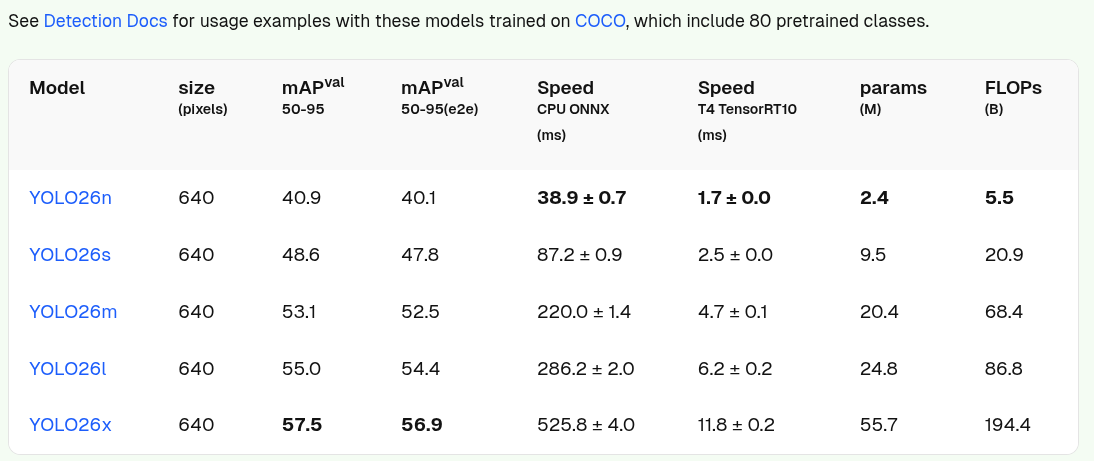

<img src="https://cdn.ul.run/i/1b042c1a3e984e8d2eb58c2af3c53965.avif" alt = "Таблица скорости работы и точности моделей YOLO">

Модель YOLOV11 вышла в сентябре 2024 года

Модель YOLOV26 вышла в январе 2026 года

Существуют варианты модели для
- детекции, детекции с учётом ориентации
- классификации
- instance segmentation
- pose \ keypoints extraction

В моделях реализован методы отслеживания - `track()`

Документация: https://docs.ultralytics.com/#introduction

### Загрузка предварительно обученной модели

In [5]:
from ultralytics import YOLO

In [6]:
from pathlib import Path

MODELS_DIR = Path("models/")
IMAGES_DIR = Path("../images/")   # общая папка с картинками для всех примеров

# doc: https://docs.ultralytics.com/reference/engine/model/#ultralytics.engine.model.Model
model = YOLO(MODELS_DIR / "yolo11n.pt")

# model.info(detailed = True) 
# doc: shows detailed information about the model layers and parameters 🤷

In [7]:
# имена классов, которые распознаёт обученная модель
LabelNames = model.names
LabelNames

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou

### Распознавание на изображении

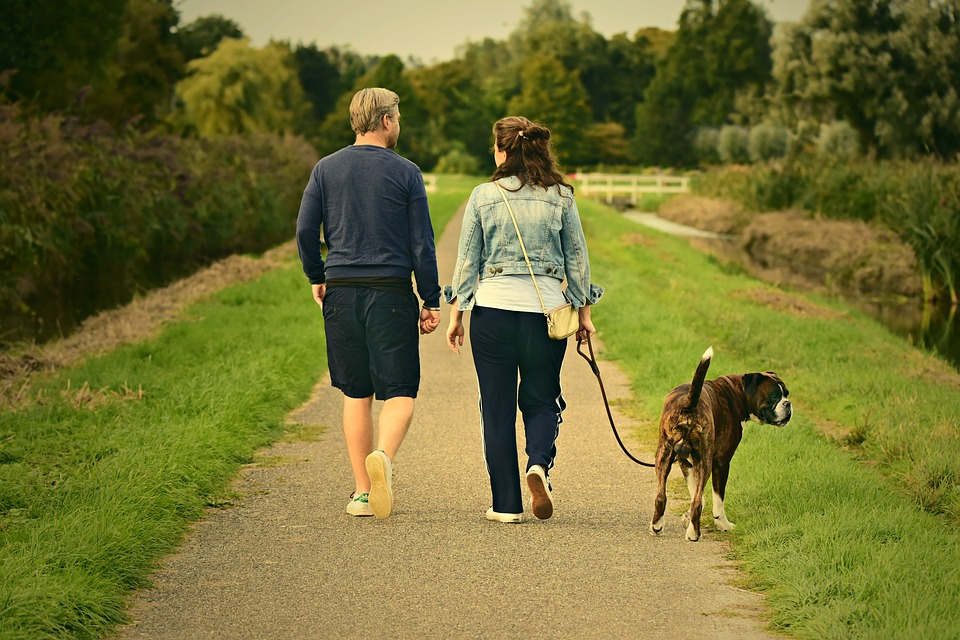

In [15]:
# изображение для проверки
!wget https://deepstackpython.readthedocs.io/en/latest/_images/test-image3.jpg --quiet -nc -P ../images/ # -nc -- не перезаписывать файл есть он есть
image_path = IMAGES_DIR / "test-image3.jpg"

from PIL import Image
img = Image.open(image_path)
img

In [17]:
# применение модели
result = model( image_path )        # возвращает список из объектов Results, длина списка = кол-во изображений
# классы
[ LabelNames[int(c)] for c in result[0].boxes.cls ]

# result[0].boxes -- содержит результаты детекции, включая координаты ограничивающих рамок, классы и вероятности
# result[0].boxes.cls -- список из номеров классов, которые были распознаны на изображении
# result[0].boxes.xyx1 -- список из координат ограничивающих рамок в формате [x_min, y_min, x_max, y_max]
# result[0].boxes.conf -- список из вероятностей (confidence) для каждого распознанного объекта
# result[0].plot() -- картинка (numpy array, с порядком цветовых каналов: BGR) с наложенными ограничивающими рамками и метками классов
# Документация 
# - по классу Results - https://docs.ultralytics.com/reference/engine/results
# - по классу Boxes   - https://docs.ultralytics.com/reference/engine/results#ultralytics.engine.results.Boxes

['person', 'person', 'dog', 'handbag']

#### Нарисовать рамки объектов

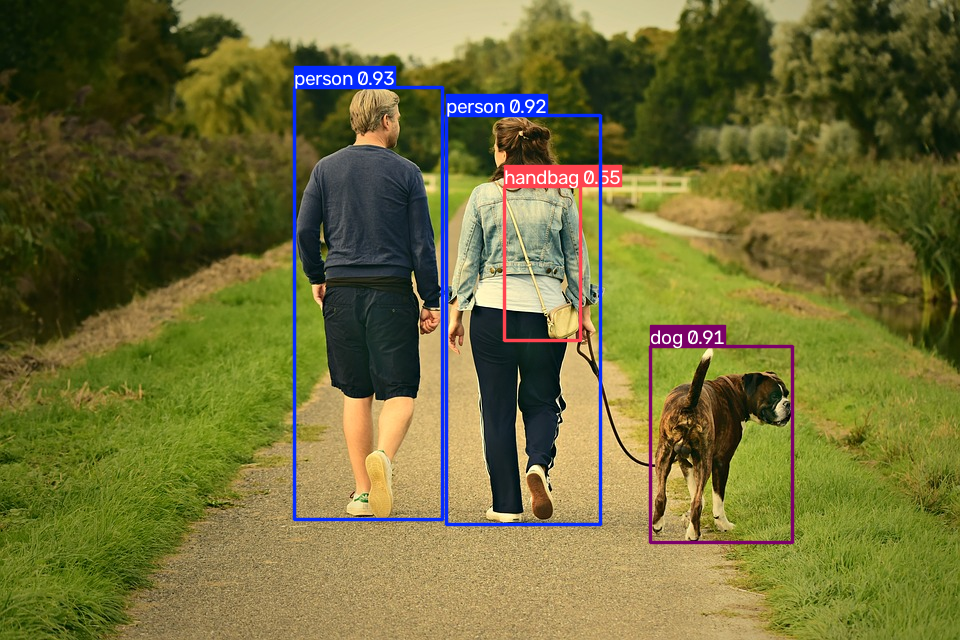

: 

In [ ]:
# Готовая рамка
annotated_frame = result[0].plot()
Image.fromarray(annotated_frame[:, :, ::-1] )

In [11]:
# своя рамка
# чтобы легче отличать рамку от фона стоит рисовать её пунктиром

def draw_dashed_rectangle(draw, xy, fill=None, width=1):
    """Рисует пунктирный прямоугольник"""
    x1, y1, x2, y2 = xy
    
    def draw_dashed_line(draw, start, end, dash_length=5, gap_length=5, fill='white', width=1):
        x1, y1 = start
        x2, y2 = end
        
        if x1 == x2:  # vertical line
            for y in range(y1, y2, dash_length + gap_length):
                draw.line([(x1, y), (x1, min(y + dash_length, y2))], fill=fill, width=width)
        else:  # horizontal line
            for x in range(x1, x2, dash_length + gap_length):
                draw.line([(x, y1), (min(x + dash_length, x2), y1)], fill=fill, width=width)
    # todo: пофиксить, чтобы можно было задавать два цвета и рисовать в любом направлении
    draw_dashed_line(draw, (x1, y1), (x2, y1))  # Top
    draw_dashed_line(draw, (x2, y1), (x2, y2))  # Right
    draw_dashed_line(draw, (x1, y2), (x2, y2))  # Bottom
    draw_dashed_line(draw, (x1, y1), (x1, y2), )  # Left

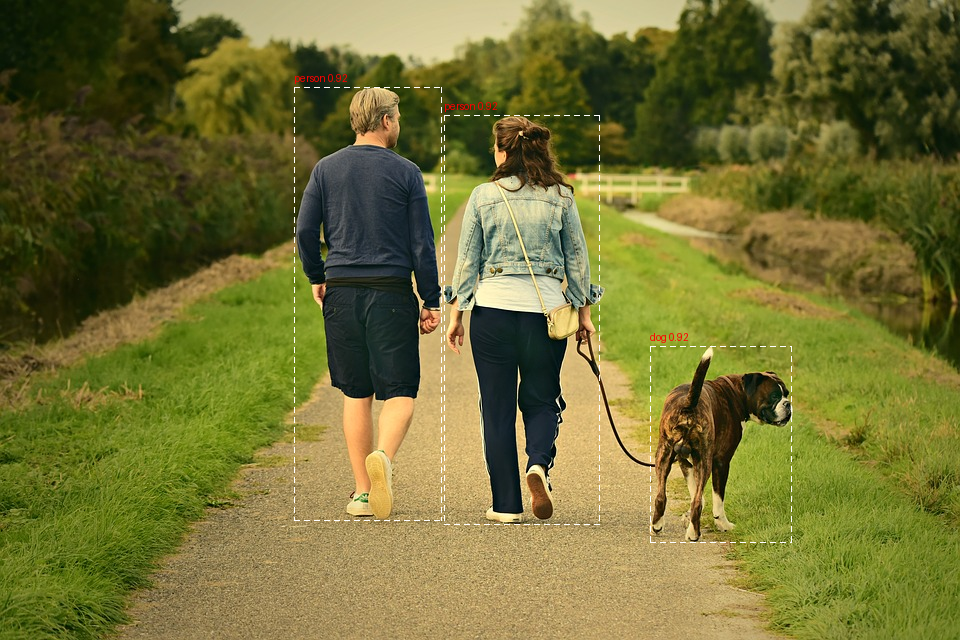

In [12]:
from PIL import Image, ImageDraw, ImageFont
image = Image.open(image_path)

draw = ImageDraw.Draw(image)
font = ImageFont.load_default()

for result in result:
    boxes = result.boxes
    for box in boxes:
        # Координаты рамки
        x1, y1, x2, y2 = map(int, box.xyxy[0])

        # Класс и уверенность
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        label = f"{result.names[class_id]} {confidence:.2f}"

        # Рисуем рамку
        # draw.rectangle([x1, y1, x2, y2], outline="yellow", width=2)
        draw_dashed_rectangle(draw, [x1, y1, x2, y2], fill="yellow")
        # Добавляем текст
        draw.text((x1, y1 - 15), label, fill="red", font=font, size=20)

# Сохранение изображения
# image.save("output_pil.jpg")
image

# Распознавание по видео с камеры

In [13]:
import cv2
import logging
import time
from ultralytics import YOLO


# person - 0
# cat - 15
# wine glass - 40
# cup - 41
# cell phone - 67
# book - 73


# Отключение логирования, чтобы не выводить информацию про детекцию на каждом кадре
logging.getLogger("ultralytics").setLevel(logging.CRITICAL)
model = YOLO(MODELS_DIR / "yolo11s.pt", verbose=False)  # Подключи свою модель

# Открытие веб-камеры
cap = cv2.VideoCapture(0)


# для подсчёта FPS
prev_time = 0

if not cap.isOpened():
    print("Не удалось открыть камеру")
    exit()

while True:
    # Получение текущего времени для подсчёта FPS
    current_time = time.time()
    # Вычисление FPS
    fps = 1 / (current_time - prev_time)
    prev_time = current_time

    # Чтение фрейма с камеры
    ret, frame = cap.read()
    if not ret:
        print("Не удалось получить фрейм")
        break

    # Выполнение предсказания с помощью YOLO
    results = model(frame, max_det=10, conf=0.5, classes = [0,15, 40, 41, 67, 73])
    # максимум 10 объектов, минимальная уверенность детекции любого? объекта - conf, classes - набор классов, которые нужно искать

    # Проход по результатам
    for result in results:
        boxes = result.boxes
        for box in boxes:
            # Координаты рамки
            x1, y1, x2, y2 = map(int, box.xyxy[0])

            # Класс и уверенность
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            label = f"{result.names[class_id]} {confidence:.2f}"

            # Рисование рамки и подписи
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 1)
            cv2.putText(frame, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # Отображение FPS на видео
    fps_text = f"FPS: {fps:.0f}"
    cv2.putText(frame, fps_text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)

    # Показ фрейма с результатами
    cv2.imshow("YOLO Detection", frame)

    # Выход по нажатию клавиши 'q'
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Закрытие всех окон
cap.release()
cv2.destroyAllWindows()


KeyboardInterrupt: 